In [1]:
import numpy as  np
import matplotlib.pyplot as plt 
from scripts.ansatz import DomainWallAnsatz, Ansatz
from scripts.compiled import Problem, AnswerShooting
import sympy as sm
from scipy.ndimage import shift
import scipy.optimize as opt
import sympy.matrices as mtx
from scipy.interpolate import Akima1DInterpolator
import os 
from tqdm import tqdm
import seaborn as sns


from tqdm import tqdm
from scipy.integrate import solve_ivp
from scripts.mm.experiment import Experiment
from scripts.read_field import read_dir
from scripts.scatter import ranged_search
import scripts.scientific
from scripts.scientific import colors
from scripts.mm.fit import fit, trajectory

$$
\frac{1}{r}\partial_r[r \partial_r \theta(r)] - \frac{1 + r^2}{2r^2}\sin 2\theta(r) + 2 (\beta + \epsilon) {\color{blue}\cos \chi} \cfrac{\sin^2\theta(r)}{r} + 
\gamma[({\color{blue}b_r\cos\chi + \cancel{b_\phi}^{\ 0} \sin\chi})\cos \theta(r) + b_z \sin(\theta_r)]=0
$$

## Solver

In [163]:
from scripts.compiled import field_a, field

problem = Problem(epsilon=0.5, beta=-3, chi=1, distance=0)
dr = 1e-5
damping = 0.01
gamma_damping = 0.01
# default ansatz
ansatz = Ansatz(
    theta = lambda r, x, _: DomainWallAnsatz.theta(r, x[0], x[1]),
    theta_r = lambda r, x, _: DomainWallAnsatz.theta_r(r, x[0], x[1]),
)

center = [0,0]
start_force = None
start_M = None 

def quad(r, dens):
    return np.diff(r) @ (np.copy(dens[:-1]) + dens[1:])

def q0(R, w):
    return 1 / np.tanh(R / w) / w

def q1(R,w):
    density = 0.5 * problem.r * np.sin(ansatz.theta(problem.r, [R,w], problem)) ** 2
    return quad(problem.r, density)

def q2(R,w):
    density = 0.25 * problem.r * (
        ansatz.theta_r(problem.r, [R,w], problem) ** 2 + np.sin(ansatz.theta(problem.r, [R,w], problem)) ** 2 / problem.r ** 2
    )
    return quad(problem.r, density)

def q3(R,w):
    density = 2 / w * problem.r * np.sin(ansatz.theta(problem.r, [R,w], problem) / 2) ** 2

    return -q0(R,w) * q1(R,w) * R / w + quad(problem.r, density)

def q4(R, w):
    density = 0.5 * problem.r ** 3 * (
        ansatz.theta_r(problem.r, [R,w], problem) ** 2 + np.sin(ansatz.theta(problem.r, [R,w], problem)) ** 2 / problem.r ** 2
    )

    return -q1(R,w) * ((R * q0(R,w)) ** 2 + 1) / w ** 2 - 2 * q0(R,w) * q3(R,w) * R / w + quad(problem.r, density) / w**2

eta_fixed = False 

def step(t, y):
    global start_M, start_force
    a = y[0]
    phi = y[1]
    R = y[2]
    w = y[3]
    
    if eta_fixed == False:
        h = y[4]
        v_x = y[5]
        v_y = y[6]
    else:
        h = 0
        v_x = y[4]
        v_y = y[5]

    # getting distances 
    problem.distance = a
    def vortex_distance(a, phi, vx=v_x, vy=v_y):
        return np.sqrt((a * np.cos(phi) - vx) ** 2 + (a * np.sin(phi) - vy) ** 2)
    problem.distance_vortex = vortex_distance(a, phi)
    
    # real energy density 
    theta = ansatz.theta(problem.r, [R, w], problem)
    theta_r = ansatz.theta_r(problem.r, [R, w], problem)
    exchange_density = ( 2 * problem.r * theta_r + np.sin(2 * theta));
    
    _beta = problem.beta
    _epsilon = problem.epsilon
    problem.beta = _beta * np.cos(h)
    problem.epsilon = _epsilon * np.cos(h)
    problem.helicity = h

    dR = 1e-5
    dPhi = 1e-7
    energy_R = (problem.answer_energy(AnswerShooting(problem.r, ansatz.theta(problem.r, [R + dR, w], problem), ansatz.theta_r(problem.r, [R + dR, w], problem)))-problem.answer_energy(AnswerShooting(problem.r, theta, theta_r))) / dR
    energy_w = (problem.answer_energy(AnswerShooting(problem.r, ansatz.theta(problem.r, [R, w + dR], problem), ansatz.theta_r(problem.r, [R, w + dR], problem)))-problem.answer_energy(AnswerShooting(problem.r, theta, theta_r))) / dR
    
    theta = ansatz.theta(problem.r, [R, w], problem)
    theta_r = ansatz.theta(problem.r, [R, w], problem)
    def energy(problem):
        return problem.answer_energy(AnswerShooting(problem.r, theta, theta_r))

    energy_0 = energy(problem)
    distance_vortex_0 = problem.distance_vortex
    distance_0 = problem.distance

    problem.distance_vortex = vortex_distance(a, phi + dPhi)
    energy_phi = -(energy(problem) - energy_0) / dPhi

    problem.distance_vortex = vortex_distance(a + dR, phi)
    problem.distance = a + dR
    energy_L = -(energy(problem) - energy_0) / dR

    problem.distance_vortex = vortex_distance(a, phi, v_x + dR, v_y)
    problem.distance = distance_0
    energy_vx = -(energy(problem) - energy_0) / dR
    
    problem.distance_vortex = vortex_distance(a, phi, v_x, v_y + dR)
    problem.distance = distance_0
    energy_vy = -(energy(problem) - energy_0) / dR

    problem.distance_vortex = distance_vortex_0
    problem.distance = distance_0


    # differentiating 
    # energy_0 = energy(problem)
    # distance_vortex_0 = problem.distance_vortex
    # problem.distance_vortex = vortex_distance(a, phi + dPhi)
    # energy_phi = (energy(problem) - energy_0) / dPhi
    # problem.distance_vortex = vortex_distance(a + dR, phi)
    # energy_L = (energy(problem) - energy_0) / dR
    # problem.distance_vortex = distance_vortex_0
    # energy_vx = -(energy_L * np.cos(phi) - energy_phi * np.sin(phi))
    # energy_vy = -(energy_L * np.sin(phi) + energy_phi * np.cos(phi))
    # problem.distance += dR
    # energy_L -= (energy(problem) - energy_0) / dR
    # problem.distance = a

    magnetic_energy_density_h  = problem.magnetic_energy_density(problem.r, theta, -np.sin(h))
    magnetic_energy_h = np.pi * np.diff(problem.r) @ (np.copy(magnetic_energy_density_h[:-1]) + magnetic_energy_density_h[1:])
    energy_h = - np.sin(h) * problem.field_energy(
        problem.r, 
        theta,
        theta_r
    ) + magnetic_energy_h

    Q0 = q0(R,w)
    Q1 = q1(R,w)
    Q2 = q2(R,w)
    Q3 = q3(R,w)
    Q4 = q4(R,w)

    if eta_fixed == True:
        D = np.array([
            [Q2, 0,         0,            0,       0, 0],
            [0,  Q2 * a**2, 0,            0,       0, 0],
            [0,  0,         Q0 ** 2 * Q1, Q0 * Q3, 0, 0],
            [0,  0,         Q0 * Q3     , Q4,      0, 0],
            [0,  0,         0           , 0,      0, 0],
            [0,  0,         0           , 0,      0, 0],
        ]);
        G = np.array([
            [0,  -a, 0, 0, 0, 0],
            [a,   0, 0, 0, 0, 0],
            [0,   0, 0, 0, 0, 0],
            [0,   0, 0, 0, 0, 0],
            [0,   0, 0, 0, 0, 0],
            [0,   0, 0, 0, 0, 0],
        ]);
        H = np.array([
            [0,  0, 0, 0, 0, 0],
            [0,  0, 0, 0, 0, 0],
            [0,  0, 0, 0, 0, 0],
            [0,  0, 0, 0, 0, 0],
            [0,  0, 0, 0, 1, 0],
            [0,  0, 0, 0, 0, 1],
        ]);
        
        M = damping * D + gamma_damping * H - G
        b = -np.array([energy_L, energy_phi, energy_R, energy_w, energy_vx, energy_vy]) / (8 * np.pi)
        problem.beta = _beta
        problem.epsilon = _epsilon

        if (t == 0):
            start_M = M
            start_force = b

        # y_new = np.linalg.inv(M).T @ b
        y_new = np.linalg.lstsq(M, b, rcond=False)[0]
        return y_new

    D = np.array([
        [Q2, 0,         0,            0,       0,  0, 0],
        [0,  Q2 * a**2, 0,            0,       0,  0, 0],
        [0,  0,         Q0 ** 2 * Q1, Q0 * Q3, 0,  0, 0],
        [0,  0,         Q0 * Q3     , Q4,      0,  0, 0],
        [0,  0,         0,            0,       Q1, 0, 0],
        [0,  0,         0,            0,       0,  0, 0],
        [0,  0,         0,            0,       0,  0, 0],

    ]);
    G = np.array([
        [0,  -a,        0,   0,   0      , 0, 0],
        [a,   0,        0,   0,   0      , 0, 0],
        [0,   0,        0,   0,   Q0 * Q1, 0, 0],
        [0,   0,        0,   0,   Q3     , 0, 0],
        [0,   0, -Q0 * Q1, -Q3, 0      , 0, 0],
        [0,   0,        0,   0,   0      , 0, 0],
        [0,   0,        0,   0,   0      , 0, 0],
    ]);
    H = np.array([
            [0,  0, 0, 0, 0, 0, 0],
            [0,  0, 0, 0, 0, 0, 0],
            [0,  0, 0, 0, 0, 0, 0],
            [0,  0, 0, 0, 0, 0, 0],
            [0,  0, 0, 0, 0, 0, 0],
            [0,  0, 0, 0, 0, 1, 0],
            [0,  0, 0, 0, 0, 0, 1],
        ]);

    M = damping * D + gamma_damping * H - G
    b = -np.array([energy_L, energy_phi, energy_R, energy_w, energy_h, energy_vx, energy_vy]) / (8 * np.pi)
    if (t == 0):
        start_M = M
        start_force = b

    problem.beta = _beta
    problem.epsilon = _epsilon

    # y_new = np.linalg.inv(M).T @ b
    y_new = np.linalg.lstsq(M, b, rcond=False)[0]
    
    return y_new

In [108]:
def likely_rw():
    solutions = problem.probe_shooting(problem.r)
    if len(solutions) > 1:
        print(len(solutions))
    rs = np.array([problem.answer_R(ans) for ans in solutions])
    ws = np.array([
        opt.curve_fit(lambda x, R, w: DomainWallAnsatz.theta(x, R, w), ans.r, ans.theta, p0=[1,1])[0][1] for ans in solutions
        ])
    idx = np.argmin(rs[rs > 0.1])
    return rs[rs > 0.1][idx], np.abs(ws[rs > 0.1][idx])

In [109]:
def solve_for(
        beta = 0,
        gamma=0,
        pos = [-5,0],
        vortex_pos = [0,0],
        R = None,
        w = None, 
        eta = 0,
        count = 1000,
        time = 50,
        alpha=0.5,
        sigma=0.5,
        fix_eta = False,
        tol=1e-5,
):
    global damping
    global gamma_damping
    global center
    global problem
    problem.beta=beta
    problem.gamma = gamma
    problem.distance=np.sqrt((pos[0] - center[0]) **2 + (pos[1] - center[1]) ** 2)
    vx = vortex_pos[0] - center[0]
    vy = vortex_pos[1] - center[1]
    angle = np.atan2(pos[1] - center[1], pos[0] - center[0])
    damping = alpha
    gamma_damping = sigma
    if (R is None) or (w is None):
        R, w = likely_rw()

    if fix_eta:
        y0 = [problem.distance, angle, R, w, vx, vy]
    else:
        y0 = [problem.distance, angle, R, w, eta, vx, vy]


    global eta_fixed
    eta_fixed = fix_eta

    stop_on_center = lambda t, y: y[0] - tol
    stop_on_center.terminal = True

    stop_on_destroy = lambda t, y: y[2] - tol
    stop_on_destroy.terminal = True
    
    stop_on_destroy = lambda t, y: y[2] - tol
    stop_on_destroy.terminal = True

    sol = solve_ivp(
        step,
        t_span=[0,time],
        y0=y0,
        t_eval=np.linspace(0,time,count+1),
        method='LSODA',
        events=[stop_on_destroy, stop_on_center]
    )
    sol.y[:2] = np.vstack([sol.y[0] * np.cos(sol.y[1]) + center[0], sol.y[0] * np.sin(sol.y[1]) + center[1]])
    if fix_eta:
        sol.y[4:] = np.vstack([sol.y[4] + center[0], sol.y[5] + center[1]])
    else:
        sol.y[5:] = np.vstack([sol.y[5] + center[0], sol.y[6] + center[1]])
    return sol 

## Path analysis

#### Dimensional

In [147]:
def force(y):
    a = y[0]
    phi = y[1]
    R = y[2]
    w = y[3]
    v_x = y[4]
    v_y = y[5]
    def vortex_distance(a, phi, vx=v_x, vy=v_y):
        return np.sqrt((a * np.cos(phi) - vx) ** 2 + (a * np.sin(phi) - vy) ** 2)

    problem.distance = a
    problem.distance_vortex = vortex_distance(a, phi)
    theta = ansatz.theta(problem.r, [R, w], problem)
    theta_r = ansatz.theta(problem.r, [R, w], problem)
    def energy(problem):
        return problem.answer_energy(AnswerShooting(problem.r, theta, theta_r))

    energy_0 = energy(problem)
    distance_vortex_0 = problem.distance_vortex
    distance_0 = problem.distance

    dR = 1e-5
    dPhi = 1e-7
    problem.distance_vortex = vortex_distance(a, phi + dPhi)
    energy_phi = -(energy(problem) - energy_0) / dPhi / a

    problem.distance_vortex = vortex_distance(a + dR, phi)
    problem.distance = a + dR
    energy_L = -(energy(problem) - energy_0) / dR
    

    problem.distance_vortex = vortex_distance(a, phi, v_x + dR, v_y)
    problem.distance = distance_0
    energy_vx = -(energy(problem) - energy_0) / dR
    
    problem.distance_vortex = vortex_distance(a, phi, v_x, v_y + dR)
    problem.distance = distance_0
    energy_vy = -(energy(problem) - energy_0) / dR

    return [energy_L, energy_phi, energy_vx, energy_vy]

##### Скирмион (-3,0) + Вихрь (0, 3, gamma=1.15)

In [159]:
problem.beta = 0
problem.gamma = 0
problem.epsilon=0.45
R, w = likely_rw()

In [186]:
problem.epsilon=0.45
center=[1,0]
sol=solve_for(
    beta=0,
    gamma=0,
    pos=[-1,0],
    vortex_pos=[1,-1],
    R=0.7,
    w=0.63,
    eta=0,
    time=50,
    count=1000,
    alpha=0.5,
    sigma=1,
    fix_eta=True
)

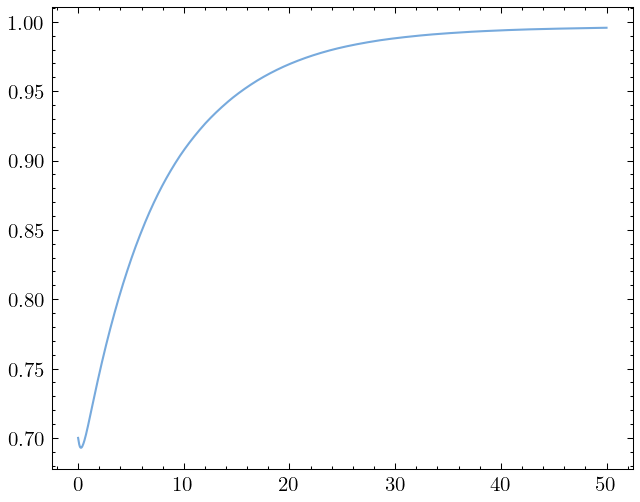

In [191]:
plt.plot(sol.t, sol.y[2])
# plt.axhline(R)

[  5.9675  -0.     -12.01    -5.601   -0.      -0.    ]


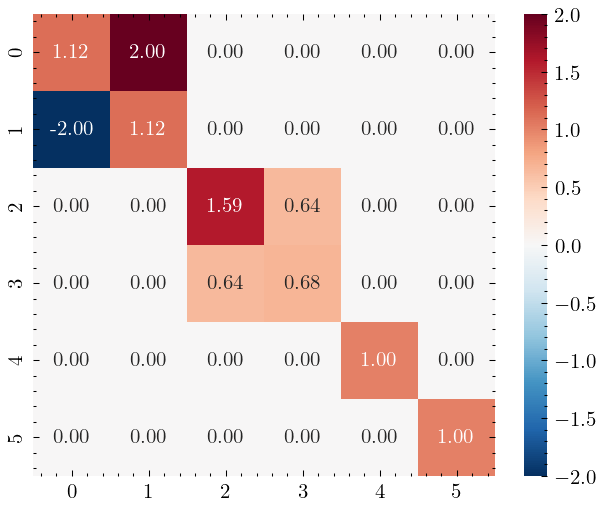

In [182]:
start_M[1,1] /= 4
sns.heatmap(
    start_M,
    annot=True,
    cmap="RdBu_r",
    fmt=".2f",
    square=True,
)
print(-start_force.round(decimals=5) * 50)

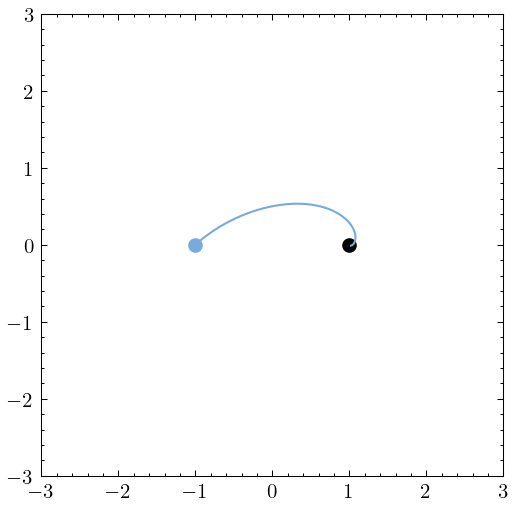

In [183]:
fig, ax = plt.subplots()
ax.scatter(sol.y[0,0], sol.y[1,0])
ax.plot(sol.y[0], sol.y[1])
# ax.scatter(sol.y[5,0], sol.y[6,0])
# ax.plot(sol.y[5], sol.y[6])
ax.scatter(*center, color='k')
ax.set_ylim([-3,3])
ax.set_xlim([-3,3])
ax.set_aspect('equal')

##### Скирмион (-5,0) + Поле (0,0, beta=-3) + Вихрь (0, 3, gamma=1.15)

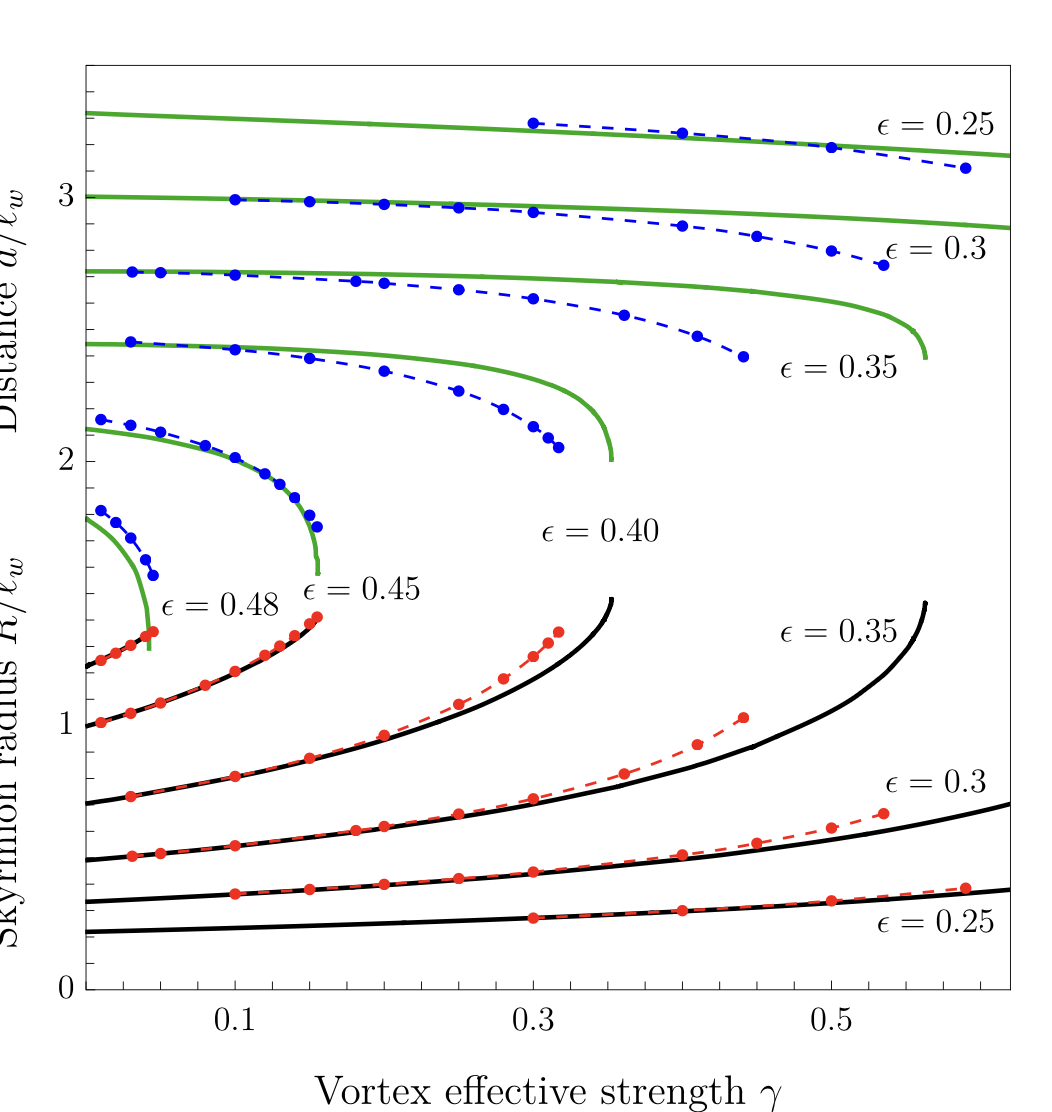

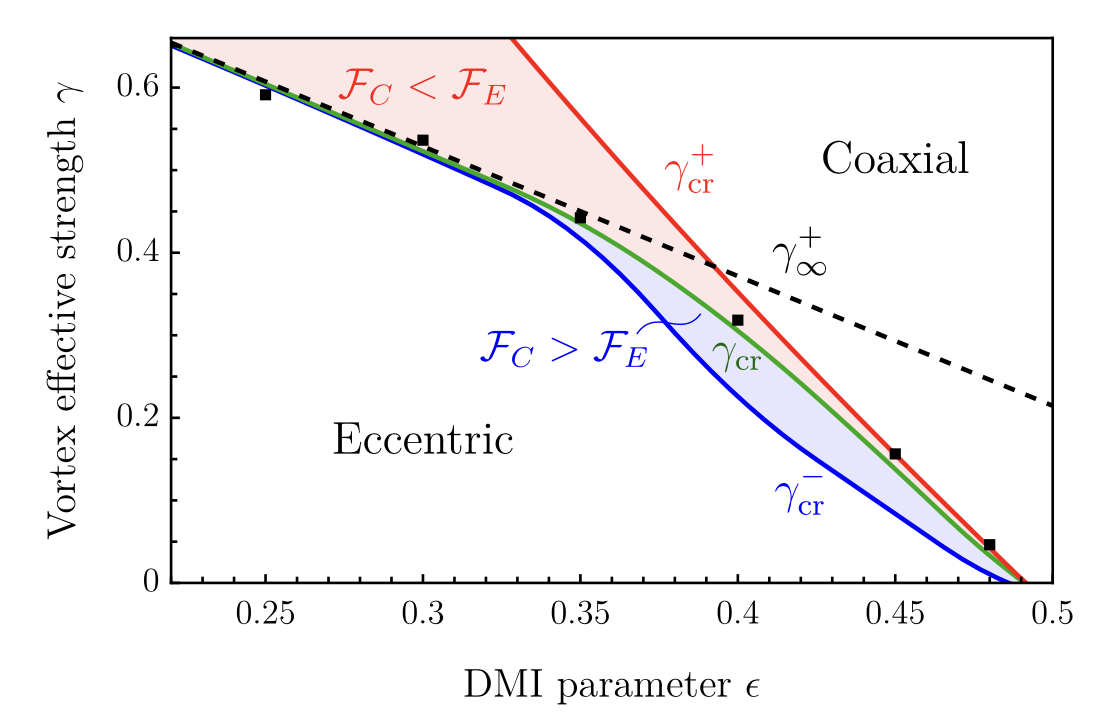

In [1]:
problem.epsilon=0.45
sol=solve_for(
    beta=0,
    gamma=0,
    pos=[-3,0],
    vortex_pos=[0,-4],
    R=1,
    w=0.8,
    eta=0,
    time=77.5,
    count=1000,
    alpha=0.05,
    sigma=5,
    fix_eta=True
)

NameError: name 'problem' is not defined

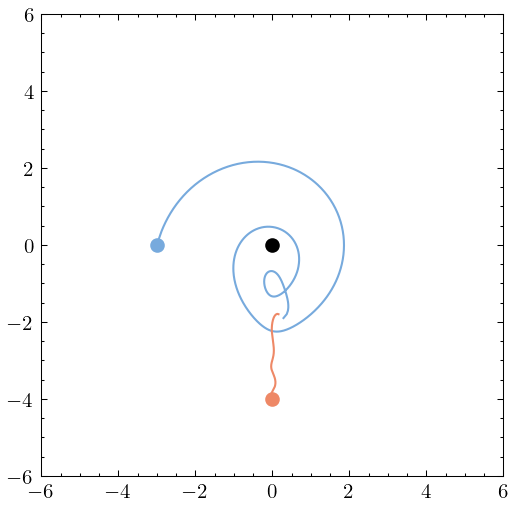

In [182]:
fig, ax = plt.subplots()
ax.scatter(sol.y[0,0], sol.y[1,0])
ax.plot(sol.y[0], sol.y[1])
ax.scatter(sol.y[4,0], sol.y[5,0])
ax.plot(sol.y[4], sol.y[5])
ax.scatter(0, 0, color='k')
ax.set_ylim([-6,6])
ax.set_xlim([-6,6])
ax.set_aspect('equal')

In [43]:
270 / 3 * 3600

324000.0

In [46]:
time = 2.26727e-08
t0 = time / 60
0.37 нс

3.7787833333333335e-10

(-6.0, 6.0)

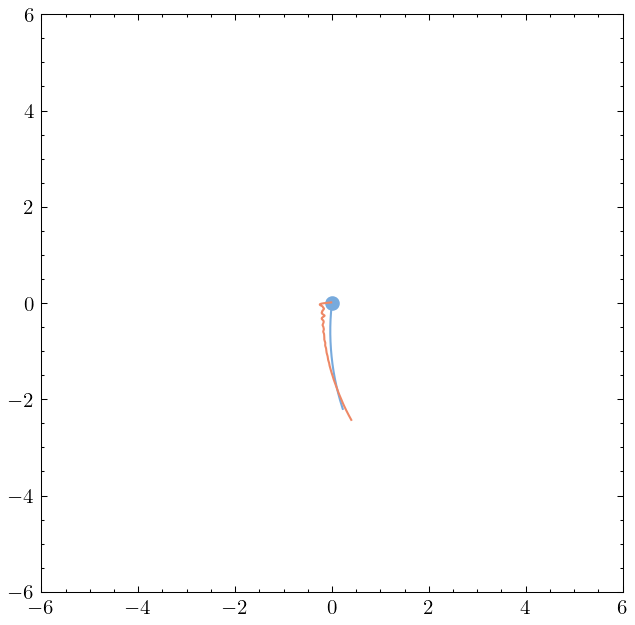

In [42]:
plt.subplots(figsize=(5,5))
plt.plot(sol.y[0] + 5, sol.y[1])
plt.scatter(sol.y[0][:1] + 5, sol.y[1][:1])
plt.plot(mm_positive[0][:270], mm_positive[1][:270])

plt.xlim([-6,6])
plt.ylim([-6,6])


In [36]:
path = os.path.join("./old")
frame = [0,0]
runs = sorted([os.path.join(path, d) for d in os.listdir(path) if d.startswith("drive-")])[frame[0]:frame[1] + 1]
data_positive = np.concat([read_dir(run) for run in runs])[:100]

ex = Experiment(
    Ms=1e5,
    dx=2.5e-9,
    width=500e-9,
    height=500e-9
)
mm_positive = np.array(trajectory(data_positive, ex, method='charge', smooth=1e-8))[:,:-1] * 10**7



Error reading file skyrmion_system-Oxs_TimeDriver-Magnetization-0000000-1652400.omf: Cannot read file old/drive-0/skyrmion_system-Oxs_TimeDriver-Magnetization-0000000-1652400.omf. The file seems to be in binary format (8 bytes) but the check value is not correct: Expected 123456789012345.0, got -2.904509606729748e-11.


(-6.0, 6.0)

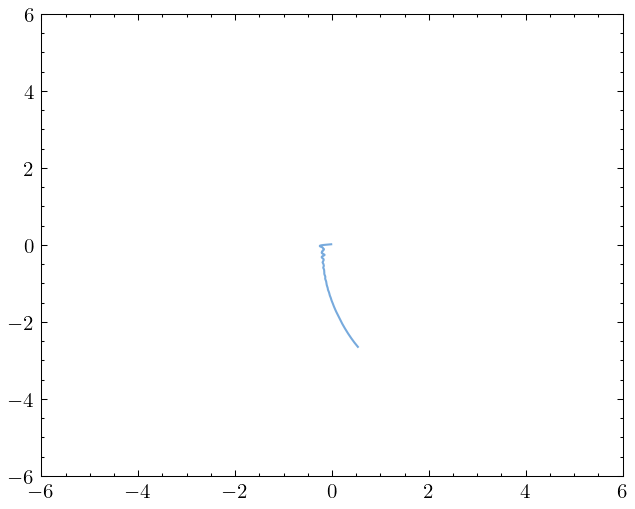

#### Destruction example 

/Users/nazarsi/Desktop/science/skyrmions-v2/scripts/ansatz.py:65: RuntimeWarning: overflow encountered in cosh
  return - 4 * np.sinh(R / delta) * np.cosh(r / delta) / (delta * (np.cosh(2 * r / delta) + 2 * np.sinh(R / delta) ** 2 - 1))
/Users/nazarsi/Desktop/science/skyrmions-v2/scripts/ansatz.py:61: RuntimeWarning: overflow encountered in sinh
  return 2 * np.arctan(np.sinh(R / delta) / np.sinh(r/ delta))
/Users/nazarsi/Desktop/science/skyrmions-v2/scripts/ansatz.py:65: RuntimeWarning: invalid value encountered in divide
  return - 4 * np.sinh(R / delta) * np.cosh(r / delta) / (delta * (np.cosh(2 * r / delta) + 2 * np.sinh(R / delta) ** 2 - 1))


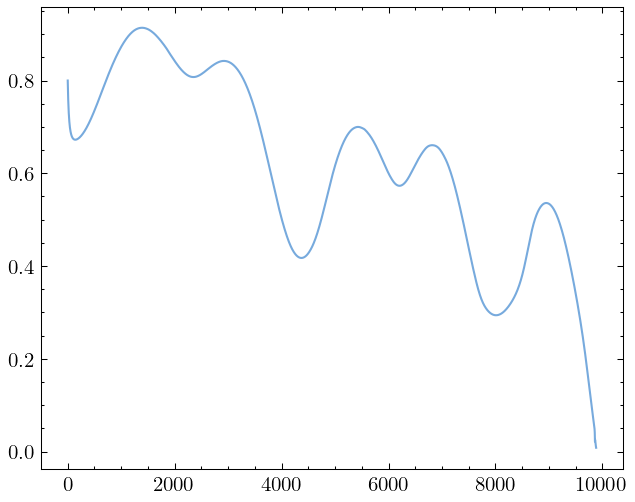

In [166]:
problem.epsilon=0.3
sol=solve_for(
    beta=-1.5,
    pos=[0.01,0],
    R=0.8,
    w=1,
    eta=0,
    time=46.5,
    count=10000,
    alpha=0.05,
    fix_eta=False
)
problem.epsilon=0.5
plt.plot(sol.y[2])

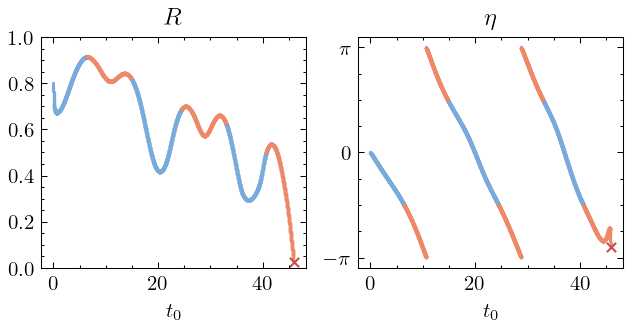

In [184]:

fig, axs = plt.subplots(1,2, figsize=(5,2))
cutoff = 140
sol.y[4] = (sol.y[4] + np.pi) % (2 * np.pi) - np.pi
positive = np.abs(sol.y[4,:-cutoff]) < np.pi / 2

axs[0].scatter(sol.t[:-cutoff][positive],sol.y[2,:-cutoff][positive], s=0.3)
axs[0].scatter(sol.t[:-cutoff][~positive],sol.y[2,:-cutoff][~positive], s=0.3)
axs[1].scatter(sol.t[:-cutoff][positive],sol.y[4,:-cutoff][positive], s=0.3)
axs[1].scatter(sol.t[:-cutoff][~positive],sol.y[4,:-cutoff][~positive], s=0.3)
axs[0].set_xlabel("$t_0$")
axs[0].set_title("$R$")
axs[0].set_ylim([0,1])
axs[1].set_xlabel("$t_0$")
axs[1].set_yticks([-np.pi, 0, np.pi], [r'$-\pi$', '$0$', r'$\pi$'])
axs[1].set_title(r"$\eta$")

axs[0].scatter(sol.t[-cutoff-1], sol.y[2,-cutoff-1], s=20, marker='x', color=colors[3])
axs[1].scatter(sol.t[-cutoff-1], sol.y[4,-cutoff-1], s=20, marker='x', color=colors[3])

#### Rest

In [15]:
path = os.path.join("./02-attraction/skyrmion_system")
frame = [3,5]
runs = sorted([os.path.join(path, d) for d in os.listdir(path) if d.startswith("drive-")])[frame[0]:frame[1] + 1]
data = np.concat([read_dir(run) for run in runs])
experiments = [Experiment.load(run) for run in runs]

In [27]:
ps = []
X, Y = None, None
for m in tqdm(data):
    p0 = ps[-1] if len(ps) else None 
    p, X, Y = fit(m, experiment=experiments[0], return_grid=True, p0=p0, method="Nelder-Mead")
    ps.append(p)

ps = np.array(ps)

100%|██████████| 3/3 [00:08<00:00,  2.68s/it]


In [17]:
plt.plot(ps[:,0], ps[:,1])

TypeError: list indices must be integers or slices, not tuple

TypeError: list indices must be integers or slices, not tuple

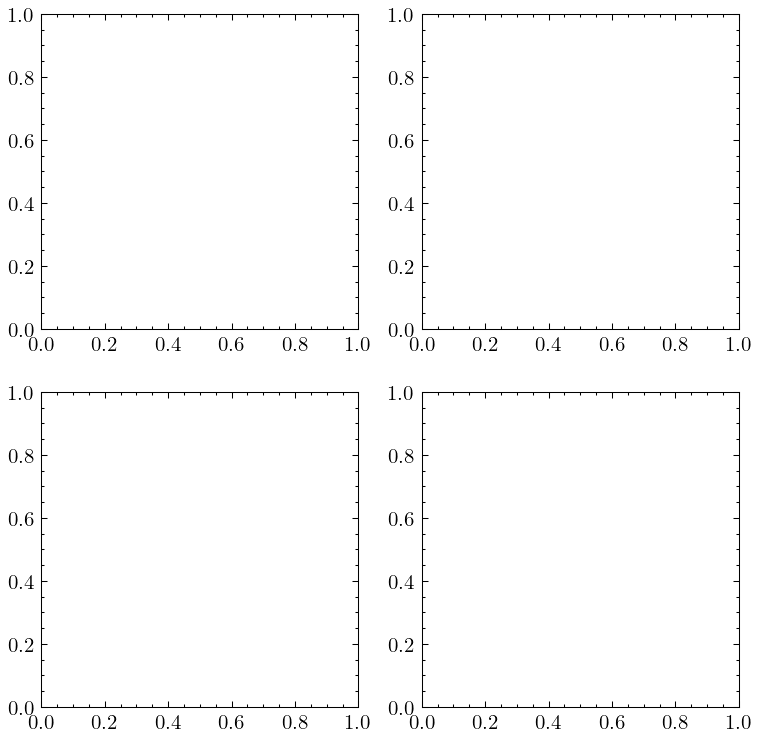

In [18]:
fig, axs = plt.subplots(2,2, figsize=(6,6))
axs[0,0].plot(np.atan2(ps[:,1],ps[:,0]), ps[:,2])
axs[0,0].set_title("$R(\\varphi)$")
axs[1,0].plot(ps[:,4])
axs[1,0].set_title("$\\eta$")
axs[0,1].plot(ps[:,2])
axs[0,1].set_title("$R$")
axs[1,1].plot(ps[:,3])
axs[1,1].set_title("$\\delta$")

In [19]:
from typing import Literal
from tqdm import tqdm
from scipy.interpolate import make_smoothing_spline

def trajectory(data, experiment: Experiment, method: Literal['center', 'charge'] = 'center', lam=1e-11):
    xs = np.array([])
    ys = np.array([])
    W = experiment.width / experiment.dx
    H = experiment.height / experiment.dx
    X, Y = np.meshgrid(np.arange(-W, W) * experiment.dx, -np.arange(-H, H) * experiment.dx)
    for i in range(len(data)):
        if method == 'center':
            weight = (1- data[i,:,:,2]) ** 2
        if method == 'charge':
            weight = np.sum(data[i] * np.linalg.cross(np.gradient(data[i], axis=0), np.gradient(data[i], axis=1)), axis=2)
        norm = np.sum(weight)

        x = np.sum(weight * X) / norm
        y = np.sum(weight * Y) / norm
        xs = np.append(xs, x)
        ys = np.append(ys, y)

    xs = xs - experiment.vortex_to[0]
    ys = ys - experiment.vortex_to[1]
    t = np.linspace(0, 1, len(xs))
    t_fine = np.linspace(0, 1, len(xs) * 3)
    xs, ys =  make_smoothing_spline(t,xs, lam=lam)(t_fine), make_smoothing_spline(t,ys, lam=lam)(t_fine)

    return xs, ys

In [20]:
xs, ys = trajectory(data, experiments[0], method='center', lam=1e-20)
xs_2, ys_2 = trajectory(data, experiments[0], method='charge', lam=1e-20)

plt.plot(xs, ys, label='Mass')

plt.plot(ps[:,0], ps[:,1], label="Ansatz")
plt.plot(xs_2, ys_2, label="Topological charge")
plt.legend()

ValueError: ``x`` and ``y`` length must be at least 5

In [21]:
problem = Problem(epsilon=0.5, beta=-3, chi=1, distance=0)
center = [0, 0]
start = [3, 0]
problem.beta = 2
problem.distance = 3
fix_eta = False 
sol_positive = solve_for(
    problem.beta, start,
    count=10000,
    R=1,
    w=0.75,
    eta=0,
    time=250,
    alpha=0.05
).y
sol_fixed = solve_for(
    problem.beta, start,
    count=10000,
    R=1,
    w=0.75,
    eta=0,
    time=250,
    alpha=0.05,
    fix_eta=True
).y

In [22]:
from scripts.scatter import Search

res, = Search.ranged(beta=2, count=10, epsilon=0.5, chi=[1], problem=problem, distances=np.linspace(0,3, 100))

100%|██████████| 100/100 [00:04<00:00, 20.80it/s]


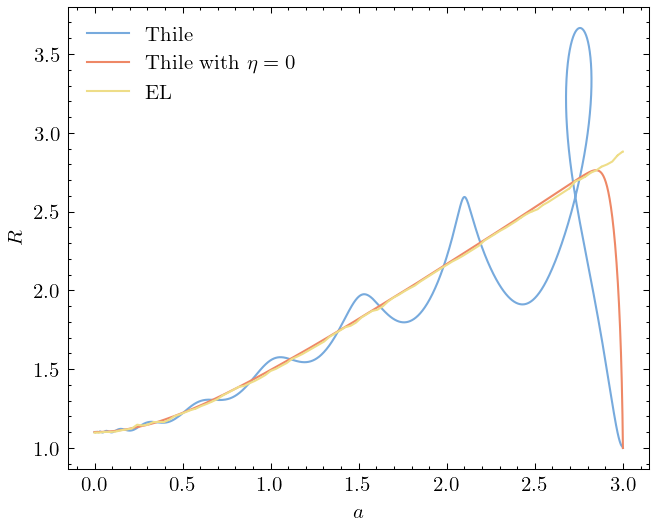

In [24]:
# plt.plot(np.sqrt(ps[:,0] ** 2 + ps[:,1] ** 2), ps[:,2], label="MM ansatz fit")
plt.plot(np.sqrt(sol_positive[0] ** 2 + sol_positive[1] ** 2), sol_positive[2], label="Thile")
plt.plot(np.sqrt(sol_fixed[0] ** 2 + sol_fixed[1] ** 2), sol_fixed[2], label="Thile with $\\eta = 0$")
plt.plot(res.distances, res.radii, label="EL")
plt.ylabel("$R$")
plt.xlabel("$a$")
plt.legend()

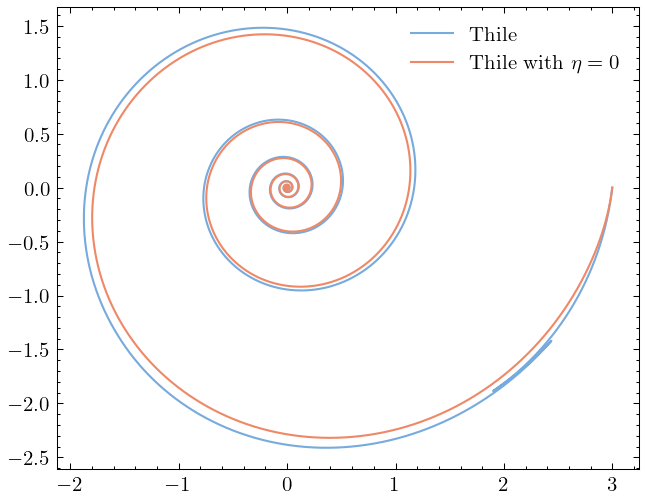

In [26]:
# plt.plot(ps[:,0] , ps[:,1], label="MM ansatz fit")
plt.plot(sol_positive[0] , sol_positive[1], label="Thile")
plt.plot(sol_fixed[0] , sol_fixed[1], label="Thile with $\\eta = 0$")
plt.legend()

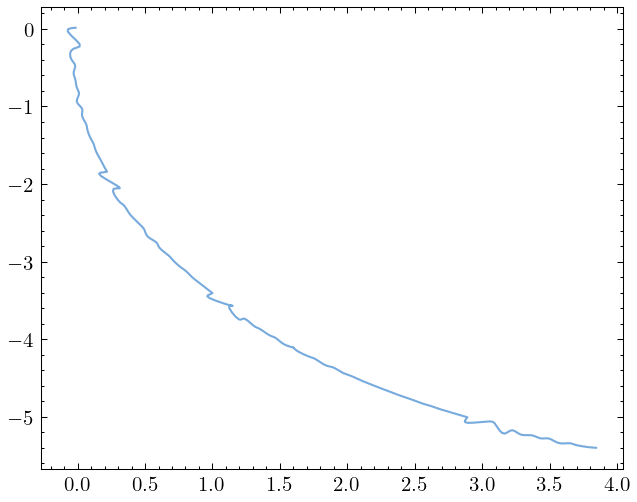

In [60]:
path = os.path.join("./01-repulsion/skyrmion_system")
runs = sorted([os.path.join(path, d) for d in os.listdir(path) if d.startswith("drive-")])[5:]
data_negative = [read_dir(run) for run in runs]
experiments_negative = [Experiment.load(run) for run in runs]

ts = [trajectory(d, e, method='center', lam=1e-6) for d, e in zip(data_negative, experiments_negative)]
xs, ys = [], []
curr = [np.float64(0), np.float64(0)]
for t in ts:
    xs = [*xs, *t[0]]
    ys = [*ys, *t[1]]

plt.plot(xs,ys)

#### Speed

In [6]:
solutions = []
betas = np.arange(1,8.5,0.5)
for beta in betas:
    problem = Problem(epsilon=0.3, beta=beta, chi=1,)
    sol=solve_for(
        beta=beta,
        pos=[8,0],
        R=0.3484731589359635,
        w=0.3,
        eta=0,
        time=30000,
        count=300000,
        alpha=0.05,
        fix_eta=True
    )
    sol.d = np.sqrt(sol.y[0] ** 2  + sol.y[1] ** 2)
    sol.phi = np.unwrap(np.atan2(sol.y[1], sol.y[0]))
    solutions.append(sol)

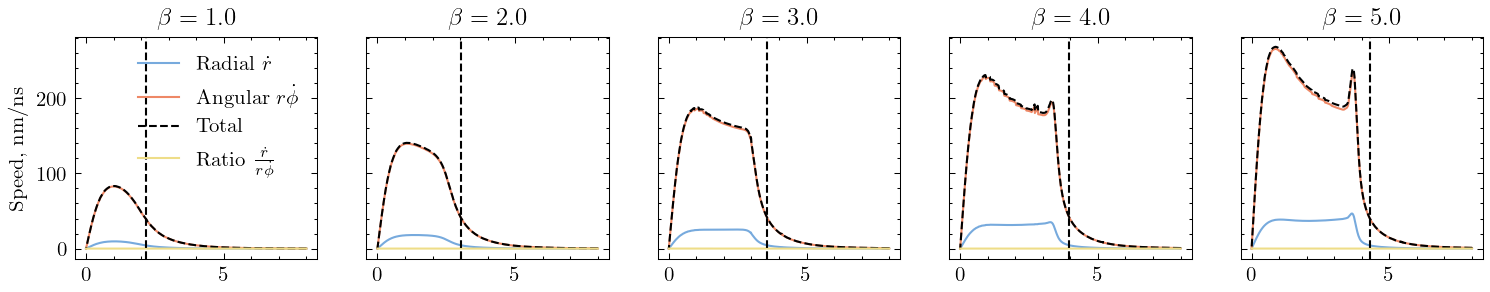

In [25]:
fig, ax = plt.subplots(1, 5, figsize=(10,2), sharex=True, sharey=True)
fig.tight_layout()


for i, frame in enumerate([0,2,4,6,8]):
    sol = solutions[frame]
    d = sol.d[:-1]
    dimensional_factor = 100 / 0.25
    d_t = np.diff(sol.d) / np.diff(sol.t) * dimensional_factor
    phi_t = sol.d[:-1] * np.diff(sol.phi) / np.diff(sol.t) * dimensional_factor
    v = np.sqrt(phi_t ** 2 + d_t ** 2)
    ax[i].plot(d,np.abs(d_t), label='Radial $\\dot r$')
    ax[i].plot(d,np.abs(phi_t), label='Angular $r \\dot \\phi$')
    ax[i].plot(d,v, label='Total', linestyle='--', color='k')
    ax[i].plot(d,d_t/phi_t, label='Ratio $\\frac{\\dot r}{r\\dot \\phi}$')
    idx = np.argmin(np.abs(sol.y[2,:np.argmax(sol.y[2])] - sol.y[2,-1]))
    ax[i].axvline(sol.d[idx], color='k', linestyle='--')
    ax[i].set_title(f'$\\beta={betas[frame]}$')
ax[0].legend()
ax[0].set_ylabel("Speed, nm/ns")
plt.savefig('./speed.pdf',dpi=10)

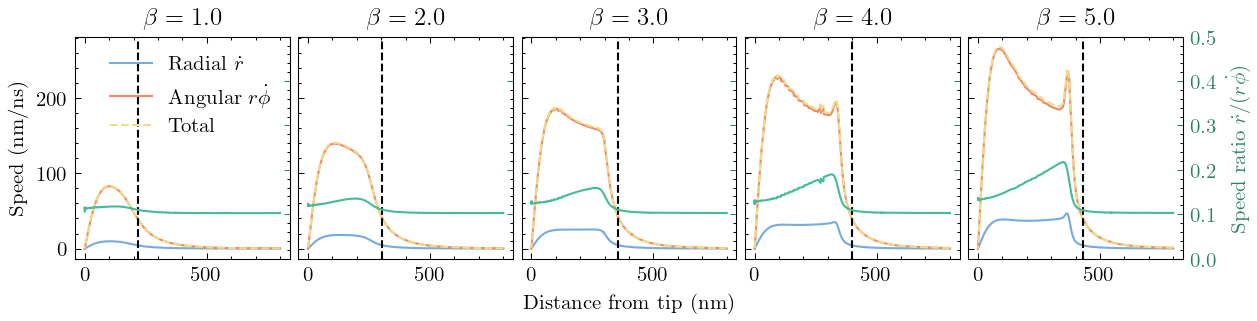

In [55]:
fig, ax = plt.subplots(1, 5, figsize=(8,2), sharex=True, sharey=True)
fig.tight_layout()

for i, frame in enumerate([0,2,4,6,8]):
    sol = solutions[frame]

    d = sol.d[:-1]
    dimensional_factor = 100 / 0.25

    d_t = np.diff(sol.d) / np.diff(sol.t) * dimensional_factor
    phi_t = sol.d[:-1] * np.diff(sol.phi) / np.diff(sol.t) * dimensional_factor
    v = np.sqrt(phi_t**2 + d_t**2)
    ratio = d_t / phi_t

    # Primary axis (speed)
    ax[i].plot(d * 100, np.abs(d_t), label=r'Radial $\dot r$')
    ax[i].plot(d * 100, np.abs(phi_t), label=r'Angular $r\dot\phi$')
    ax[i].plot(d * 100, v, '--', label='Total')

    # Secondary axis (ratio)
    tcolor = colors[5]
    ax2 = ax[i].twinx()
    ax2.plot(d * 100, ratio, color=tcolor, label=r'$\dot r/(r\dot\phi)$')
    ax2.set_ylim(0, 0.5)     # or (0,1) if you plot abs(ratio)
    ax2.tick_params(axis='y', colors='#2e8068')

    # Only label the rightmost axis to avoid clutter
    if i == len([0,2,4,6,8]) - 1:
        ax2.set_ylabel(r'Speed ratio $\dot r/(r\dot\phi)$', color='#2e8068')
    else:
        ax2.set_yticklabels([])

    idx = np.argmin(np.abs(sol.y[2,:np.argmax(sol.y[2])] - sol.y[2,-1]))
    ax[i].axvline(sol.d[idx] * 100, color='k', linestyle='--')
    ax[i].set_title(fr'$\beta={betas[frame]}$')

ax[0].set_ylabel("Speed (nm/ns)")
ax[0].legend()
fig.subplots_adjust(wspace=0.04)
ax[2].set_xlabel("Distance from tip (nm)")

plt.savefig("./article/images/speed.pdf", dpi=300, bbox_inches="tight")

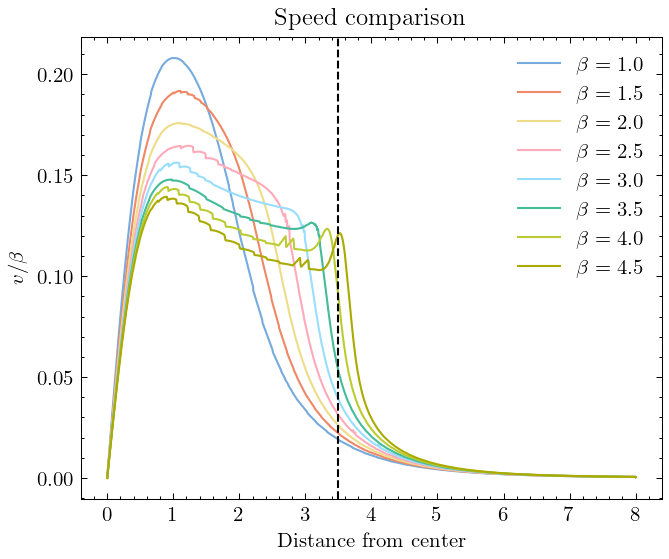

In [11]:
for i, frame in enumerate([0,2,4,6,8,10,12,14]):
    sol = solutions[frame]
    d = sol.d[:-1]
    d_t = np.diff(sol.d) / np.diff(sol.t)
    phi_t = sol.d[:-1] * np.diff(sol.phi) / np.diff(sol.t) 
    v = np.sqrt(phi_t ** 2 + d_t ** 2)
    idx = np.argmin(np.abs(sol.y[2,:np.argmax(sol.y[2])] - sol.y[2,-1]))
    # plt.axvline(sol.d[idx], color='k', linestyle='--')
    plt.plot(d,v / betas[frame], label=f'$\\beta = {betas[frame]}$')
plt.axvline(3.5, color='k', linestyle='--')
plt.title(f'Speed comparison')
plt.xlabel("Distance from center")
plt.ylabel("$v / \\beta$")
plt.legend()
plt.savefig('./speed_comparison.pdf',dpi=10)

In [75]:
avg = []
avg_after = []
ds = np.linspace(0.0001, 7.99, 200)

for fixed_d in ds:
    before = []
    after = []
    for i, sol in enumerate(solutions):
        d = sol.d[:-1]
        d_t = np.diff(sol.d) / np.diff(sol.t)
        phi_t = sol.d[:-1] * np.diff(sol.phi) / np.diff(sol.t) 
        v = np.sqrt(phi_t ** 2 + d_t ** 2)
        idx = np.argmin(np.abs(sol.y[2,:np.argmax(sol.y[2])] - sol.y[2,-1]))
        limit = sol.d[idx]
        idx_2 = np.argmin(np.abs(sol.d - fixed_d))

        speed_before = v[idx_2]
        speed_after = np.mean(v[d<limit])
        after.append(speed_after / betas[i])
        before.append(speed_before / betas[i])

    avg.append(np.mean(before))
    avg_after.append(np.mean(after))
    # avg_after.append(np.mean(speed_after))
    # print(np.mean(before), np.mean(after))
    # # Before and after attraction
    # print(np.mean(after) / np.mean(before))

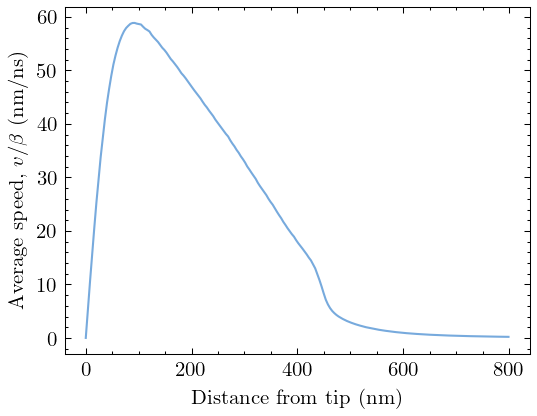

In [78]:
plt.subplots(figsize=(4,3))
plt.plot(ds * 100, np.array(avg) * 100 / 0.25)
plt.ylabel("Average speed, $v / \\beta$ (nm/ns)")
plt.xlabel("Distance from tip (nm)")
plt.savefig("./article/images/average-speed.pdf", dpi=300, bbox_inches="tight")

In [100]:
import numpy as np
from scipy.optimize import curve_fit
from scipy.stats import f

# full fit
p, _ = curve_fit(lambda x, c, k: c*x**k, ds, avg, p0=[1,-1])
rss1 = np.sum((avg - p[0]*ds**p[1])**2)

# split data
mid = len(ds)//2

ds1 = ds[:mid]
y1 = avg[:mid]

ds2 = ds[mid:]
y2 = avg[mid:]

p1, _ = curve_fit(lambda x, c, k: c*x**k, ds1, y1, p0=[1,-1])
p2, _ = curve_fit(lambda x, c, k: c*x**k, ds2, y2, p0=[1,-1])

rss2 = (
    np.sum((y1 - p1[0]*ds1**p1[1])**2)
    + np.sum((y2 - p2[0]*ds2**p2[1])**2)
)

n = len(ds)

# parameters
p_single = 2
p_double = 4

F = ((rss1-rss2)/(p_double-p_single)) / (rss2/(n-p_double))
p_value = 1 - f.cdf(F, p_double-p_single, n-p_double)

print(F, p_value)

103.3497267093557 1.1102230246251565e-16


We reject power dependence.

## Comparison

In [8]:
print("Evaluating positive trajectory")
path = os.path.join("./02-attraction/skyrmion_system")
frame = [3,5]
runs = sorted([os.path.join(path, d) for d in os.listdir(path) if d.startswith("drive-")])[frame[0]:frame[1] + 1]
data_positive = np.concat([read_dir(run) for run in runs])
experiments = [Experiment.load(run) for run in runs]
exp_positive = experiments[0]
mm_positive = np.array(trajectory(data_positive, experiments[0], method='charge', smooth=1e-8))[:,:-1]


print("Evaluating negative trajectory")
path = os.path.join("./01-repulsion/skyrmion_system")
runs = sorted([os.path.join(path, d) for d in os.listdir(path) if d.startswith("drive-")])[5:]
data_negative = [read_dir(run) for run in runs]
experiments_negative = [Experiment.load(run) for run in runs]
exp_negative = experiments_negative[0]
# Removing smoothing and interpolation
mm_negative_rough = np.hstack([np.array(trajectory(d, e, method='center', smooth=0, interpolation=1)) for d, e in zip(data_negative, experiments_negative)])
# shift with respect to the tip
mm_negative_rough = mm_negative_rough - np.array(experiments_negative[0].field_to)[:,None] 

Evaluating positive trajectory


ValueError: ``x`` and ``y`` length must be at least 5

Text(0.5, 1.0, 'Trajectory')

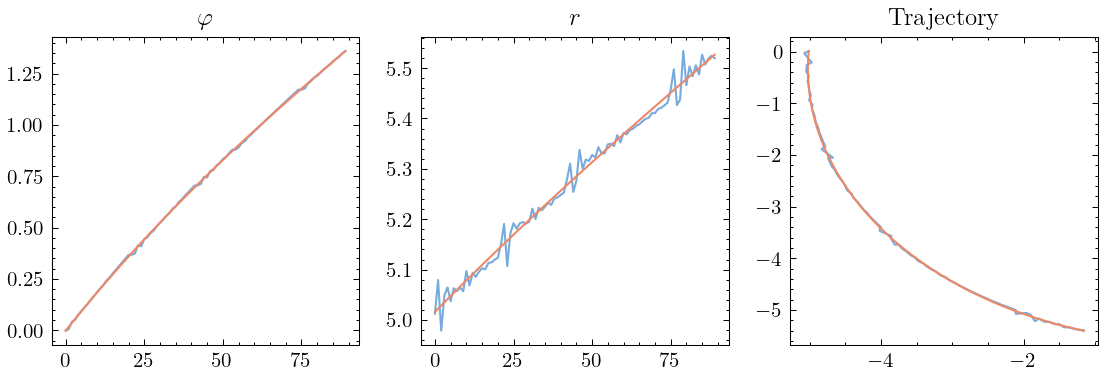

In [281]:
fig, axs = plt.subplots(1, 3, subplot_kw={'box_aspect': 1}, figsize=(9,3))
r_negative = np.linalg.norm(mm_negative_rough, ord=2, axis=0)
phi_negative = np.arctan2(mm_negative_rough[1], mm_negative_rough[0]) % (2 * np.pi) - np.pi
t = np.linspace(0,1, len(r_negative))

deg = 3 # degree of polynomial to fit 
r_poly = np.poly1d(np.polyfit(t, r_negative, deg=deg))
phi_poly = np.poly1d(np.polyfit(t, phi_negative, deg=deg))

axs[0].plot(phi_negative)
axs[0].plot(phi_poly(t))
axs[0].set_title("$\\varphi$")

axs[1].plot(r_negative)
axs[1].plot(r_poly(t))
axs[1].set_title("$r$")

mm_negative = np.array([r_poly(t) * np.cos(phi_poly(t) + np.pi), r_poly(t) * np.sin(phi_poly(t) + np.pi)])
axs[2].plot(mm_negative_rough[0], mm_negative_rough[1], label='MM rough result')
axs[2].plot(mm_negative[0], mm_negative[1], label='Trajectory ')
axs[2].set_title("Trajectory")

In [282]:
def rotate_shift(data, phi=0, x=[0,0]):
    rotated = np.array([data[0] * np.cos(phi) + data[1] * np.sin(phi), data[1] * np.cos(phi) - data[0] * np.sin(phi)])
    return rotated + np.array(x)[:,None]

def rotate_shift_mesh(mesh, phi=0, x=[0,0]):
    rotated = np.array([mesh[0] * np.cos(phi) + mesh[1] * np.sin(phi), mesh[1] * np.cos(phi) - mesh[0] * np.sin(phi)])
    return rotated + np.array(x)[:,None,None]

In [ ]:
problem.beta= -3
problem.distance = 5
problem.epsilon = 0.5
R, d = likely_rw()
print('Actual R and delta:\t','{:.3f}'.format(R), ',','{:.3f}'.format(d))
# print('MM experiment:\t\t',exp_negative.R0, ',', exp_negative.w0)

center = [0,0]
thiele_negative = solve_for(
    # -3, (mm_negative[:,0]), # starting at the same coord
    -3, [5,0],
    count=10000,
    R=R,
    w=d,
    time=239,
    alpha=0.05,
    fix_eta=True
).y

Actual R and delta:	 0.999 , 0.745


In [22]:
# plt.plot(thiele_negative[0], thiele_negative[1])

np.sum(np.sqrt(np.diff(thiele_negative[0]) ** 2 + np.diff(thiele_negative[1]) ** 2)) * 100 / (0.25 * 239) 

np.float64(12.424195856199042)

Actual R and delta:	 1.142 , 0.778


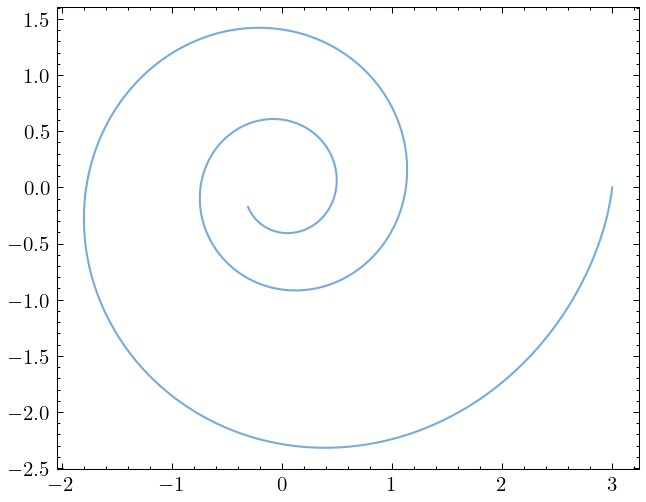

In [33]:
problem.distance = 3
problem.beta = 2
problem.epsilon = 0.5
center = [0,0]

R,d = thiele_negative[2,-1], thiele_negative[3,-1]
print('Actual R and delta:\t','{:.3f}'.format(R), ',','{:.3f}'.format(d))
# print('MM experiment:\t\t',exp_positive.R0, ',', exp_positive.w0)

thiele_positive = solve_for(
    # problem.beta, mm_positive[:,0] + np.array([-0.05, 0.3]),
    problem.beta, [3,0],
    count=10000,
    R=R,
    w=d,
    eta=0,
    time=106, # matches rotation from mm
    alpha=0.05,
    fix_eta=True
).y
plt.plot(thiele_positive[0], thiele_positive[1])
# plt.plot(mm_positive[0], mm_positive[1])


In [27]:
np.sum(np.sqrt(np.diff(thiele_positive[0]) ** 2 + np.diff(thiele_positive[1]) ** 2)) * 100 / (0.25 * 239)

np.float64(29.879754742306712)

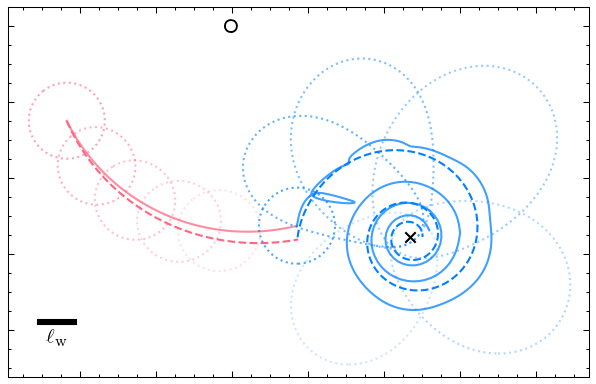

In [346]:
fig, ax = plt.subplots()
ax.set_aspect(1)
color_negative=n_color = (1,0.4,0.5)
color_positive= (0,0.5,1)

mesh_positive = np.meshgrid(
    np.arange(-exp_positive.width, exp_positive.width, exp_positive.dx),
    -np.arange(-exp_positive.height, exp_positive.height, exp_positive.dx),
)
mesh_negative = np.meshgrid(
    np.arange(-exp_negative.width, exp_negative.width, exp_negative.dx),
    -np.arange(-exp_negative.height, exp_negative.height, exp_negative.dx),
) + np.array([-5, 0])[:,None,None]

# shift positive trajectory to start from the end of negative one
positive_shift_1 = -mm_positive[:,0]
positive_shift_2 = mm_negative[:,-1]
positive_rotation = np.pi + np.pi / 5
mm_positive_shifted = rotate_shift(rotate_shift(mm_positive,x=positive_shift_1), positive_rotation, positive_shift_2)
thiele_positive_shifted = rotate_shift(rotate_shift(thiele_positive, x=positive_shift_1), positive_rotation, positive_shift_2)
positive_center = rotate_shift(rotate_shift(np.array([[0], [0]]), x=positive_shift_1), positive_rotation, positive_shift_2)
mesh_positive = rotate_shift_mesh(rotate_shift_mesh(mesh_positive, x=positive_shift_1), positive_rotation, positive_shift_2)

# rotate all trajectories
rotate_all = -np.pi / 6
mm_positive_shifted = rotate_shift(mm_positive_shifted, rotate_all)
thiele_positive_shifted = rotate_shift(thiele_positive_shifted, rotate_all)
mm_negative_shifted = rotate_shift(mm_negative, rotate_all)
thiele_negative_shifted = rotate_shift(thiele_negative, rotate_all)
positive_center = rotate_shift(positive_center, rotate_all)
mesh_positive = rotate_shift_mesh(mesh_positive, rotate_all)
mesh_negative = rotate_shift_mesh(mesh_negative, rotate_all)

# actual plotting 
plt.plot(thiele_negative_shifted[0], thiele_negative_shifted[1], linestyle='--', color=color_negative)
plt.plot(mm_negative_shifted[0], mm_negative_shifted[1], color=color_negative, alpha=0.75)
plt.plot(thiele_positive_shifted[0], thiele_positive_shifted[1], linestyle='--', color=color_positive)
plt.plot(mm_positive_shifted[0], mm_positive_shifted[1], color=color_positive, alpha=0.75)

ax.text(0, 0, r'$\boldsymbol\circ$', color='k', ha='center', va='center', fontsize=15)
plt.scatter(positive_center[0], positive_center[1], color='k', s =25, marker='x', zorder=10)

# fix limits (those will be overwritten by mesh in contour plot)
xlim = plt.xlim()
ylim = plt.ylim()

def draw_positive_mesh(i, alpha=0.5):
    plt.contour(mesh_positive[0], mesh_positive[1], data_positive[i,:,:,2], linestyles=':', levels=[0], colors=(*color_positive, alpha))

draw_positive_mesh(0  , 0.7)
draw_positive_mesh(17 , 0.6)
draw_positive_mesh(30 , 0.5)
draw_positive_mesh(50 , 0.4)
draw_positive_mesh(75 , 0.3)
draw_positive_mesh(100, 0.2)

def draw_negative_mesh(i, frame, alpha=0.5):
    center = experiments_negative[frame].vortex_to
    center = rotate_shift(np.array([[center[0]], [center[1]]]), rotate_all)[:,0]
    plt.contour(
        mesh_negative[0] - center[0], 
        mesh_negative[1] - center[1], # because image coords inverted we subtract actual center 
        data_negative[frame][i,:,:,2], linestyles=':', levels=[0], colors=(*color_negative, alpha))

draw_negative_mesh(0, 0 , 0.6)
draw_negative_mesh(15, 0, 0.5)
draw_negative_mesh(10, 1, 0.4)
draw_negative_mesh(5, 2 , 0.3)
draw_negative_mesh(7, 3 , 0.2)

# reset limits 
plt.xlim([xlim[0] - 1, xlim[1] + 2])
plt.ylim([ylim[0] -1.5, 0.5])

# coordinate system
plt.gca().set_xticklabels([])
plt.gca().set_yticklabels([])
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
import matplotlib.font_manager as fm
fontprops = fm.FontProperties(size=10)

scalebar = AnchoredSizeBar(ax.transData,
                           1, '$\\ell_{\\mathrm{w}}$', 'lower left', 
                           pad=1.35,
                           color='black',
                           frameon=False,
                           size_vertical=0.1,
                           fontproperties=fontprops)

ax.add_artist(scalebar)
plt.savefig('article/images/thiele.pdf')